In [19]:
# load graph data 

from f2f import datasets, views  # noqa: E402
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# nodes_hs = datasets.load_nodes("high_school")
# nodes_ps = datasets.load_nodes("primary_school")
# nodes_zkh = datasets.load_nodes("hospital")
contacts_hs, nodes_hs  = datasets.load_contacts("high_school")
contacts_ps, nodes_ps = datasets.load_contacts("primary_school")
contacts_zkh, nodes_zkh = datasets.load_contacts("hospital")

In [11]:
nodes = datasets.load_nodes("high_school")
print(nodes.columns)

Index(['sensor_id', 'group', 'gender', 'x', 'y'], dtype='str')


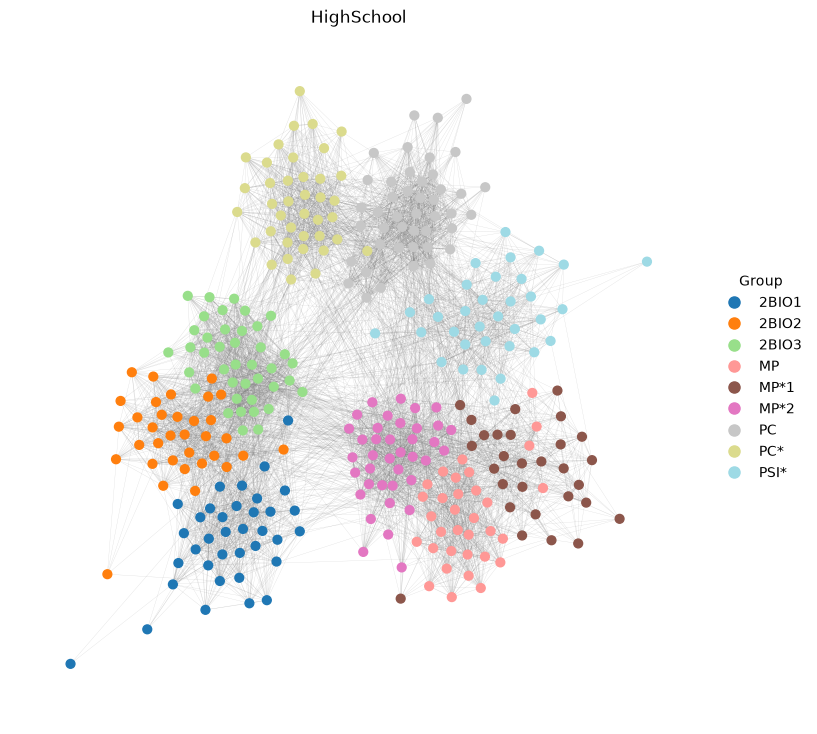

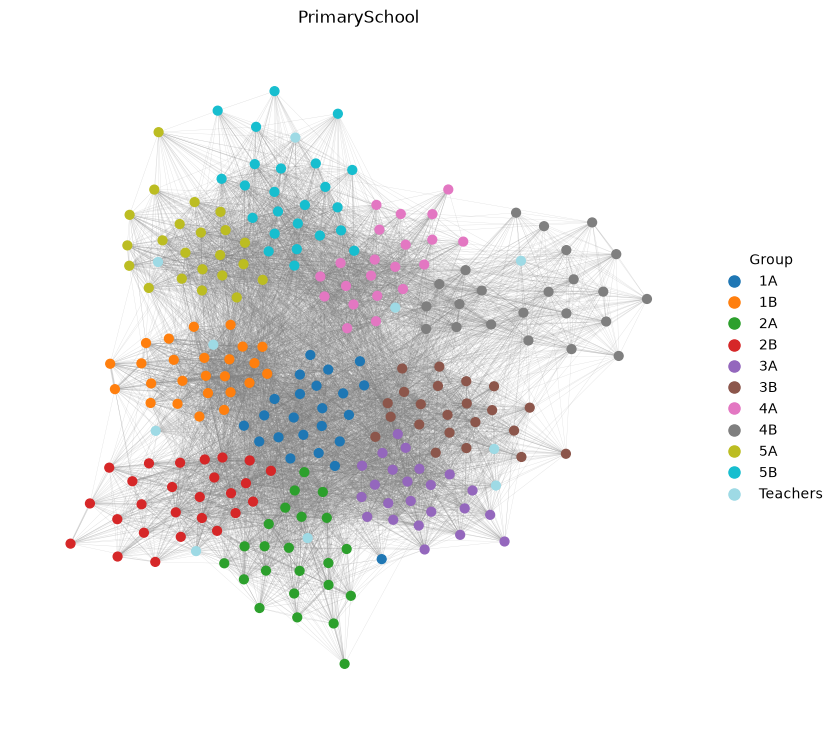

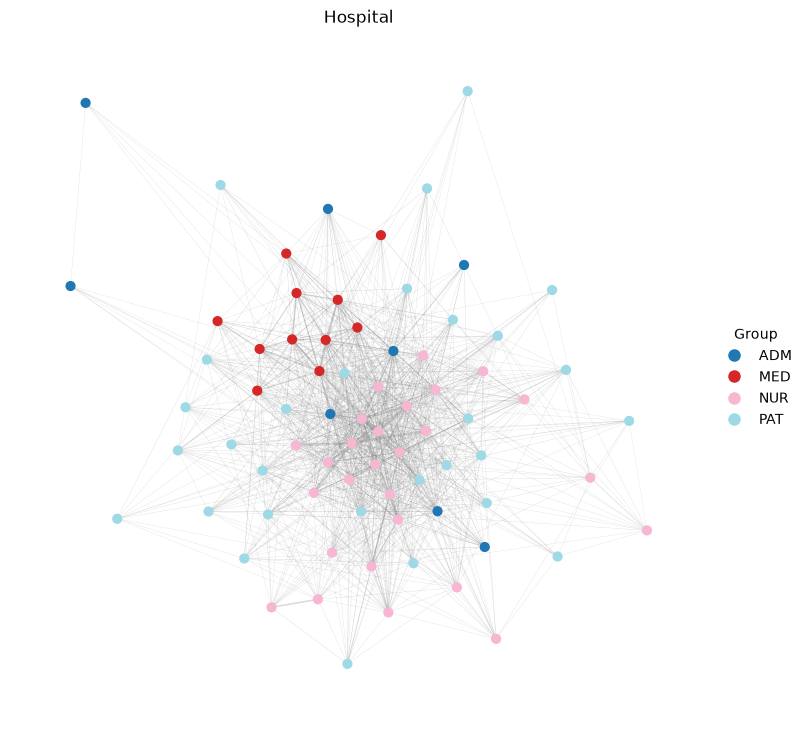

In [27]:
G_HS = views.aggregate(contacts_hs, nodes_hs)
G_PS = views.aggregate(contacts_ps, nodes_ps)
G_ZKH = views.aggregate(contacts_zkh, nodes_zkh)



def plot_aggregate(graph, nodes, title, drop_isolated=True):
  if drop_isolated:
        keep = [n for n, deg in graph.degree() if deg > 0]
        graph = graph.subgraph(keep)
  pos = {n: (nodes.at[n, "x"], nodes.at[n, "y"]) for n in graph.nodes}
  # Kleuren per groep
  groups = nodes["group"].astype("category")
  codes = groups.cat.codes
  node_colors = [codes[n] for n in graph.nodes]
  #for legend: 
  cmap_name="tab20"
  categories = list(groups.cat.categories)
  cmap = plt.get_cmap(cmap_name)
  vmax = max(len(categories) - 1, 1)

  # Lijndikte op basis van contacttijd
  weights = np.array([d["weight"] for _, _, d in graph.edges(data=True)])
  widths = 0.2 + 3 * weights / weights.max()

  fig, ax = plt.subplots(figsize=(9, 9))
  nx.draw_networkx_edges(graph, pos, ax=ax, width=widths, alpha=0.3, edge_color="gray")
  nx.draw_networkx_nodes(graph, pos, ax=ax, node_color=node_colors, cmap=cmap, node_size=40)
  ax.set_axis_off()
  ax.set_title(title)
  present = sorted({codes[n] for n in graph.nodes})
  handles = [
      Line2D([], [], marker="o", linestyle="", markersize=8,
              color=cmap(c / vmax), label=categories[c])
      for c in present
  ]
  ax.legend(handles=handles, title="Group", loc="center left",
              bbox_to_anchor=(1.0, 0.5), frameon=False)
  plt.savefig(f"../figures/graphs/{title}.png")
  

plot_aggregate(G_HS, nodes_hs, "HighSchool")
plot_aggregate(G_PS, nodes_ps, "PrimarySchool")
plot_aggregate(G_ZKH, nodes_zkh, "Hospital")



# nx.draw(G_HS, with_labels=True)